# 07 - Évolution mensuelle des prix en 2025

**Objectif** : voir si le nombre de ventes et le prix au m² varient selon le mois de l'année.

**Entrée** : `dvf_77_2025_enrichi.parquet` (13 712 ventes, sortie du notebook 06).
**Sortie** : aucun nouveau fichier (la colonne `mois` est recalculée en une ligne).

**Plan**
1. Conversion de `date_mutation` en vraie date et extraction du mois
2. Nombre de ventes par mois
3. Prix médian par mois
4. Prix médian par mois et par type de bien

## 1. Conversion de la date et extraction du mois

`date_mutation` est lue comme du texte (`str`) : pandas ne peut ni extraire le mois ni trier chronologiquement. On la convertit en `datetime64` avec `pd.to_datetime`, puis on extrait le mois avec l'accesseur `.dt`.

On rappelle que cette date est celle de la **signature de l'acte**, pas celle de la décision d'achat.

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


df = pd.read_parquet("../data/processed/dvf_77_2025_enrichi.parquet")

# 1. Vérifier le type actuel
print(df["date_mutation"].dtype)

# 2. Convertir le texte en vraie date
df["date_mutation"] = pd.to_datetime(df["date_mutation"])
print(df["date_mutation"].dtype)

# 3. Extraire le mois (1 à 12) grâce à l'accesseur .dt
df["mois"] = df["date_mutation"].dt.month

# 4. Combien de ventes par mois ?
print(df["mois"].value_counts().sort_index())

str
datetime64[us]
mois
1      929
2      976
3     1272
4      804
5      939
6     1374
7     1587
8     1015
9     1291
10    1223
11     950
12    1352
Name: count, dtype: int64


**Lecture** : les 12 mois sont présents (du 2 janvier au 31 décembre 2025). Le nombre de ventes varie presque du simple au double : 804 en avril, 1 587 en juillet. Le calendrier (jours fériés, jours ouvrés) n'explique qu'une petite partie de l'écart ; ramenées au jour ouvré, les ventes vont de 36,5 en avril à 69 en juillet. Hypothèse (non vérifiée) : pics de signature avant l'été, à la rentrée et en fin d'année.

## 2. Prix médian par mois

On compare la médiane du prix au m² à l'effectif de chaque mois.

          mediane  nb_ventes
mois                        
1     3075.630252        929
2     3090.909091        976
3     2990.100932       1272
4     3078.536075        804
5     3000.000000        939
6     3048.780488       1374
7     3157.894737       1587
8     3135.593220       1015
9     3084.070796       1291
10    3085.106383       1223
11    3015.201465        950
12    3029.512160       1352


<Axes: xlabel='mois', ylabel='mediane'>

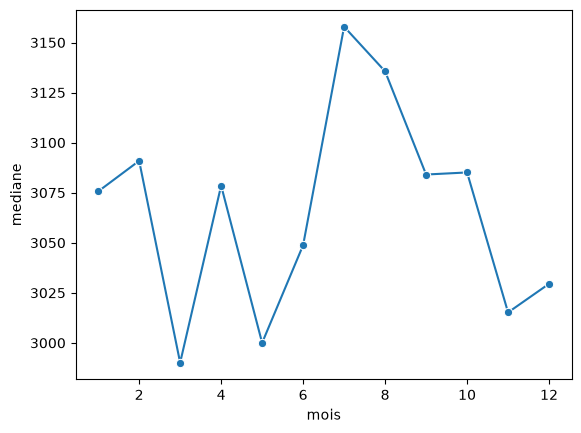

In [5]:
stats_mois = df.groupby("mois")["prix_m2"].agg(
    mediane="median",
    nb_ventes="count",
)
print(stats_mois)

sns.lineplot(data=stats_mois, x=stats_mois.index, y="mediane", marker="o")

**Lecture** : les médianes mensuelles vont de 2 990 €/m² (mars) à 3 158 €/m² (juillet), soit environ 5 % d'écart, alors que les effectifs varient du simple au double. Le prix est donc bien plus stable que le volume. Attention : l'axe vertical de seaborn est ajusté aux données et exagère visuellement les variations.

## 3. Prix médian par mois et par type de bien

La part de maisons varie de 51 % (avril) à 61 % (août). Comme les maisons sont moins chères au m² que les appartements, ce déséquilibre pourrait masquer ou créer une variation (effet de composition). On sépare donc les deux types ; l'axe est fixé de 0 à 4 000 €/m² pour voir l'amplitude réelle.

                      mediane  nb_ventes
mois type_local                         
1    Appartement  3280.853696        442
     Maison       2939.759036        487
2    Appartement  3201.562500        434
     Maison       3031.089744        542
3    Appartement  3187.500000        599
     Maison       2844.174757        673
4    Appartement  3225.892857        396
     Maison       2988.018603        408
5    Appartement  3191.489362        437
     Maison       2908.933917        502
6    Appartement  3337.349398        595
     Maison       2914.285714        779
7    Appartement  3391.304348        655
     Maison       2979.365079        932
8    Appartement  3386.250000        393
     Maison       2986.326109        622
9    Appartement  3355.990783        534
     Maison       2966.552083        757
10   Appartement  3327.777778        495
     Maison       2861.364130        728
11   Appartement  3281.250000        393
     Maison       2894.736842        557
12   Appartement

(0.0, 4000.0)

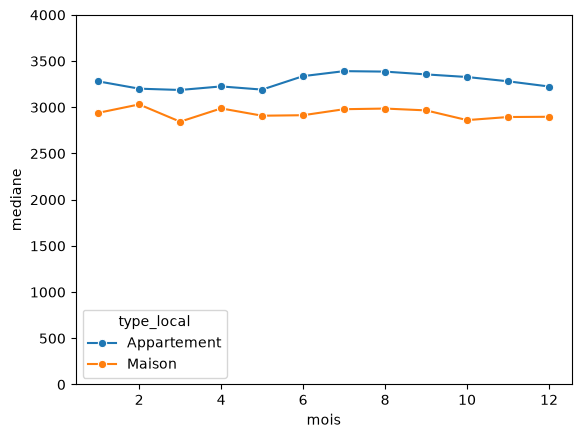

In [6]:
stats_type_mois = df.groupby(["mois", "type_local"])["prix_m2"].agg(
    mediane="median",
    nb_ventes="count",
)

print(stats_type_mois)


sns.lineplot(data=stats_type_mois, x="mois", y="mediane", hue="type_local", marker="o")
plt.ylim(0, 4000)

**Lecture** : les deux courbes sont stables. Les appartements restent entre 3 190 et 3 390 €/m² avec une légère bosse de juin à septembre (environ +6 % entre mai et juillet) ; les maisons restent entre 2 840 et 3 030 €/m² sans tendance nette.

## Conclusion

- **Volume** : le nombre de ventes varie fortement d'un mois à l'autre (de 804 en avril à 1 587 en juillet), avec des pics en juin-juillet, en septembre et en décembre. Une partie vient du nombre de jours ouvrés, le reste d'une saisonnalité du marché (hypothèse non vérifiée).
- **Prix** : le prix médian reste stable sur l'année (environ 3 000 à 3 160 €/m², soit ≈ 5 % d'écart). Séparé par type de bien, il reste stable pour les maisons et monte légèrement en été pour les appartements (≈ +6 %).
- **Limite du bruit** : une médiane calculée sur environ 1 000 ventes varie d'environ ±40 €/m² par simple effet d'échantillonnage (estimation indicative par rééchantillonnage). Les écarts observés sont du même ordre : on ne peut pas affirmer de saisonnalité des prix.
- **Limite temporelle** : on n'a qu'une seule année, donc impossible de distinguer une saisonnalité d'une tendance annuelle.
- **Pour la modélisation** : le mois est une variable à faible pouvoir explicatif sur le prix au m² ; elle peut être testée, mais ne devrait pas être prioritaire par rapport au type de bien, à la surface et à la distance à Paris.

**Fichier de référence pour la modélisation** : `dvf_77_2025_enrichi.parquet` (13 712 lignes, 15 colonnes).
**Prochaine étape** : synthèse de l'analyse exploratoire (README, résultats clés, variables retenues).